# DQN and the six Rainbow parts: probes first, CartPole second

**Code:** [`algos/dqn.py`](../algos/dqn.py) · [`double_dqn.py`](../algos/double_dqn.py) · [`dueling_dqn.py`](../algos/dueling_dqn.py) · [`per_dqn.py`](../algos/per_dqn.py) · [`n_step_dqn.py`](../algos/n_step_dqn.py) · [`c51_dqn.py`](../algos/c51_dqn.py) · [`noisy_dqn.py`](../algos/noisy_dqn.py) · [`double_q.py`](../algos/double_q.py) · [`diagnostics/probe_envs.py`](../diagnostics/probe_envs.py) · [`experiments/deep_value_sweep.py`](../experiments/deep_value_sweep.py)
**Papers:** Mnih 2013 ([PDF](../papers/deep-value/mnih-2013-atari-dqn.pdf)), Mnih 2015 ([PDF](../papers/deep-value/mnih-2015-dqn-nature.pdf)), van Hasselt 2010 ([PDF](../papers/tabular/vanhasselt-2010-doubleq.pdf)) and 2015 ([PDF](../papers/deep-value/vanhasselt-2015-double-dqn.pdf)), Schaul 2015 ([PDF](../papers/deep-value/schaul-2015-per.pdf)), Wang 2016 ([PDF](../papers/deep-value/wang-2016-dueling.pdf)), Bellemare 2017 C51 ([PDF](../papers/deep-value/bellemare-2017-distributional.pdf)), Fortunato 2017 Noisy ([PDF](../papers/deep-value/fortunato-2017-noisy-nets.pdf)), Hessel 2017 ([PDF](../papers/deep-value/hessel-2017-rainbow.pdf)) ·
**Notes:** [`papers/deep-value/notes.md`](../papers/deep-value/notes.md)

What you will see:

1. Five one-step **probe environments** with exact answers. DQN passes all five; one interface bug makes it fail all five, and probe 1 says where.
2. One DQN run on CartPole with its **health panel**: return, mean Q, TD error, gradient norm.
3. **Replay and the target network removed one at a time**, over 5 seeds.
4. **Maximisation bias**, measured exactly on a 3-state MDP: Q-learning prefers the losing branch, Double Q does not.
5. **DQN, Double, Dueling, PER, 3-step, C51 and Noisy** on CartPole, 5 seeds each, including how far each network's value estimate is from the return it actually gets.
6. **C51 learns a distribution:** checked on a coin flip whose return distribution is known exactly. **Noisy nets** learn how much noise to keep.

Sections 2, 3, 5 and 7 (first half) run live (about 2 minutes on CPU). Sections 4 and 6 are 55 runs of 100,000 steps (about 35 minutes); they are read from
`experiments/results/deep_value/`, and `python experiments/deep_value_sweep.py ablation` / `compare` regenerates them.

In [1]:
import json, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import gymnasium as gym

from algos import dqn, double_q
from diagnostics.probe_envs import run_probes, report
from envs.maximization_bias import MaximizationBias

torch.set_num_threads(1)
plt.rcParams["figure.dpi"] = 110
RESULTS = pathlib.Path("../experiments/results/deep_value") if pathlib.Path("../experiments").exists() else pathlib.Path("experiments/results/deep_value")

## 0. The problem and the data

**CartPole-v1.** A pole is hinged on a cart. Each step the agent pushes the cart left or right.
Reward is +1 for every step the pole stays up. The episode **terminates** if the pole tilts past 12° or the cart leaves the track,
and is **truncated** at 500 steps. So the best possible return is 500.

The observation is four numbers:

| column | meaning |
| --- | --- |
| `x` | cart position (−2.4 to 2.4 before termination) |
| `x_dot` | cart velocity |
| `theta` | pole angle in radians (±0.21 before termination) |
| `theta_dot` | pole angular velocity |

There is no fixed dataset. The agent collects transitions $(s, a, r, s', \text{terminated})$ as it plays.

  t       x   x_dot   theta theta_dot action reward terminated
  0   0.014  -0.023  -0.046    -0.048      1    1.0      False
  1   0.013   0.173  -0.047    -0.355      1    1.0      False
  2   0.017   0.368  -0.054    -0.662      1    1.0      False
  3   0.024   0.564  -0.067    -0.971      0    1.0      False
  4   0.035   0.370  -0.087    -0.701      0    1.0      False
  5   0.043   0.176  -0.101    -0.436      0    1.0      False
 15   0.021   0.581  -0.130    -1.339      1    1.0      False
 16   0.032   0.777  -0.157    -1.669      1    1.0      False
 17   0.048   0.974  -0.190    -2.007      1    1.0       True

random policy: episode ended after 18 steps


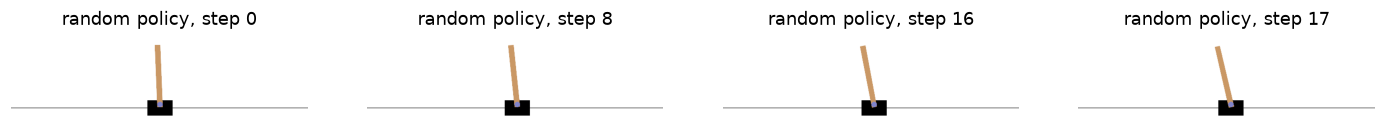

In [2]:
env = gym.make("CartPole-v1", render_mode="rgb_array")
obs, _ = env.reset(seed=0)
rng = np.random.default_rng(0)
frames, rows = [], []
for t in range(40):
    action = int(rng.integers(2))
    next_obs, reward, terminated, truncated, _ = env.step(action)
    rows.append((t, *obs, action, reward, terminated))
    if t in (0, 8, 16):
        frames.append(env.render())
    obs = next_obs
    if terminated or truncated:
        frames.append(env.render())
        break

print(f"{'t':>3} {'x':>7} {'x_dot':>7} {'theta':>7} {'theta_dot':>9} {'action':>6} {'reward':>6} {'terminated':>10}")
for r in rows[:6] + rows[-3:]:
    print(f"{r[0]:>3} {r[1]:>7.3f} {r[2]:>7.3f} {r[3]:>7.3f} {r[4]:>9.3f} {r[5]:>6} {r[6]:>6.1f} {str(r[7]):>10}")
print(f"\nrandom policy: episode ended after {len(rows)} steps")

fig, axs = plt.subplots(1, len(frames), figsize=(4 * len(frames), 2.8))
for ax, frame, t in zip(axs, frames, [0, 8, 16, len(rows) - 1]):
    ax.imshow(frame[150:330]); ax.set_title(f"random policy, step {t}"); ax.axis("off")
plt.show()

## 1. DQN in one picture

Q-learning with a network $Q_\theta$. The loss is $\mathrm{Huber}\big(Q_\theta(s,a) - [r + \gamma(1-\text{terminated})\max_{a'} Q_{\bar\theta}(s',a')]\big)$
([`algos/dqn.py:153-163`](../algos/dqn.py)). Two additions make it stable, and section 3 removes them one at a time:

- **replay buffer**: train on random old transitions, not the newest one (`buffer_size=1` removes it);
- **target network** $\bar\theta$: a frozen copy refreshed every 500 steps (`target_update=1` removes it).

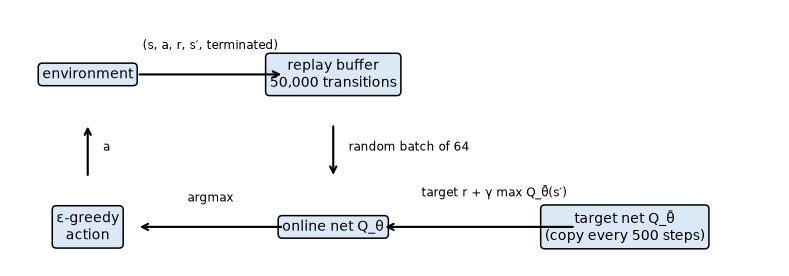

In [3]:
fig, ax = plt.subplots(figsize=(9, 3)); ax.axis("off")
boxes = {"environment": (0.1, 0.75), "replay buffer\n50,000 transitions": (0.42, 0.75), "online net Q_θ": (0.42, 0.15),
         "target net Q_θ̄\n(copy every 500 steps)": (0.8, 0.15), "ε-greedy\naction": (0.1, 0.15)}
for text, (x, y) in boxes.items():
    ax.text(x, y, text, ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round", fc="#dbe9f6"))
def arrow(a, b, label="", dx=0.0, dy=0.08, ha="center"):
    ax.annotate("", xy=boxes[b], xytext=boxes[a], arrowprops=dict(arrowstyle="->", lw=1.4, shrinkA=34, shrinkB=34))
    ax.text((boxes[a][0] + boxes[b][0]) / 2 + dx, (boxes[a][1] + boxes[b][1]) / 2 + dy, label, ha=ha, fontsize=8)
arrow("environment", "replay buffer\n50,000 transitions", "(s, a, r, s′, terminated)", dy=0.1)
arrow("replay buffer\n50,000 transitions", "online net Q_θ", "random batch of 64", dx=0.02, dy=0.0, ha="left")
arrow("target net Q_θ̄\n(copy every 500 steps)", "online net Q_θ", "target r + γ max Q_θ̄(s′)", dx=0.02, dy=0.12)
arrow("online net Q_θ", "ε-greedy\naction", "argmax", dy=0.1)
arrow("ε-greedy\naction", "environment", "a", dx=0.02, dy=0.0, ha="left")
plt.show()

## 2. Probes before CartPole

A CartPole failure could be anything. A probe failure points at one component ([`diagnostics/probe_envs.py`](../diagnostics/probe_envs.py)):

| probe | setup | exact Q | a failure means |
| --- | --- | --- | --- |
| 1 constant | 1 action, reward +1, ends | 1 | the value head or loss cannot fit a constant |
| 2 observation | obs ±1, reward = obs | ±1 | the network ignores its input |
| 3 discount | two steps, +1 at the end | γ then 1 | bootstrapping or the terminal mask is wrong |
| 4 action | reward +1 for action 0, −1 for action 1 | [1, −1] | the update ignores the action taken |
| 5 action × obs | +1 if the action matches the obs sign | [±1, ∓1] | actions and observations are not combined |

In [4]:
settings = dict(learning_starts=200, buffer_size=5_000, target_update=100)
t0 = time.time()
clean = run_probes(dqn.train, **settings)
print(report(clean)); print(f"({time.time() - t0:.0f} s)")

probe            result worst |error|   obs: learned vs expected
1 constant       pass           0.000   +0: [1.0] vs [1.0]
2 observation    pass           0.000   -1: [-1.0] vs [-1.0]; +1: [1.0] vs [1.0]
3 discount       pass           0.000   +0: [0.99] vs [0.99]; +1: [1.0] vs [1.0]
4 action         pass           0.000   +0: [1.0, -1.0] vs [1.0, -1.0]
5 action x obs   pass           0.000   -1: [1.0, -1.0] vs [1.0, -1.0]; +1: [-1.0, 1.0] vs [-1.0, 1.0]
(5 s)


Now one bug, injected in the environment wrapper rather than the algorithm: every episode end is reported as **truncation** instead of **termination**.
The algorithm code is correct, but it now bootstraps past the end of every episode.

probe            result worst |error|   obs: learned vs expected
1 constant       FAIL          23.575   +0: [24.575] vs [1.0]
2 observation    FAIL           0.181   -1: [-1.181] vs [-1.0]; +1: [0.819] vs [1.0]
3 discount       FAIL          11.549   +0: [12.24] vs [0.99]; +1: [12.549] vs [1.0]
4 action         FAIL          23.566   +0: [24.566, 22.566] vs [1.0, -1.0]
5 action x obs   FAIL           0.433   -1: [1.433, -0.567] vs [1.0, -1.0]; +1: [-0.567, 1.433] vs [-1.0, 1.0]


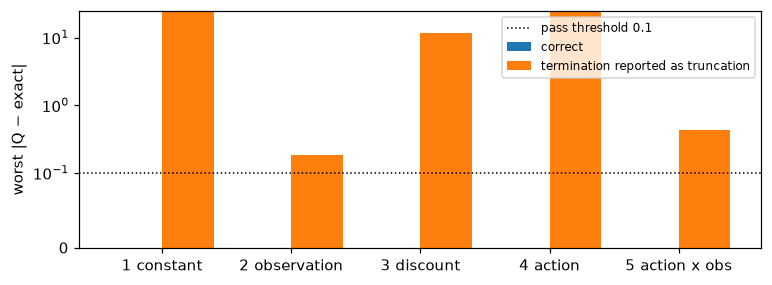

In [5]:
class TerminationAsTruncation:
    def __init__(self, env): self.env, self.action_space = env, env.action_space
    def reset(self, seed=None): return self.env.reset(seed)
    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        return obs, reward, False, terminated or truncated, info

broken = run_probes(dqn.train, wrap=TerminationAsTruncation, **settings)
print(report(broken))

fig, ax = plt.subplots(figsize=(8, 2.8))
names = [r["probe"] for r in clean]
x = np.arange(len(names))
ax.bar(x - 0.2, [r["worst_error"] for r in clean], 0.4, label="correct")
ax.bar(x + 0.2, [r["worst_error"] for r in broken], 0.4, label="termination reported as truncation")
ax.axhline(0.1, color="k", ls=":", lw=1, label="pass threshold 0.1")
ax.set_xticks(x, names); ax.set_yscale("symlog", linthresh=0.1); ax.set_ylabel("worst |Q − exact|"); ax.legend(fontsize=8)
plt.show()

Probe 1 is the diagnosis: a one-step constant reward of +1 learned as far above 1.
Nothing stops the bootstrap, so $Q = 1 + \gamma Q$ is being chased towards $1/(1-\gamma) = 100$.
On CartPole the same bug shows up only as "learns slowly" or "plateaus", which could mean anything.

## 3. One DQN run, with its health panel

100,000 steps, seed 0, greedy return over 10 fresh episodes every 5,000 steps.
Read **mean Q** against the true value: an agent that balances forever at γ = 0.99 is worth $\sum_t 0.99^t \approx 100$ (less near the 500-step limit).

(33 s)


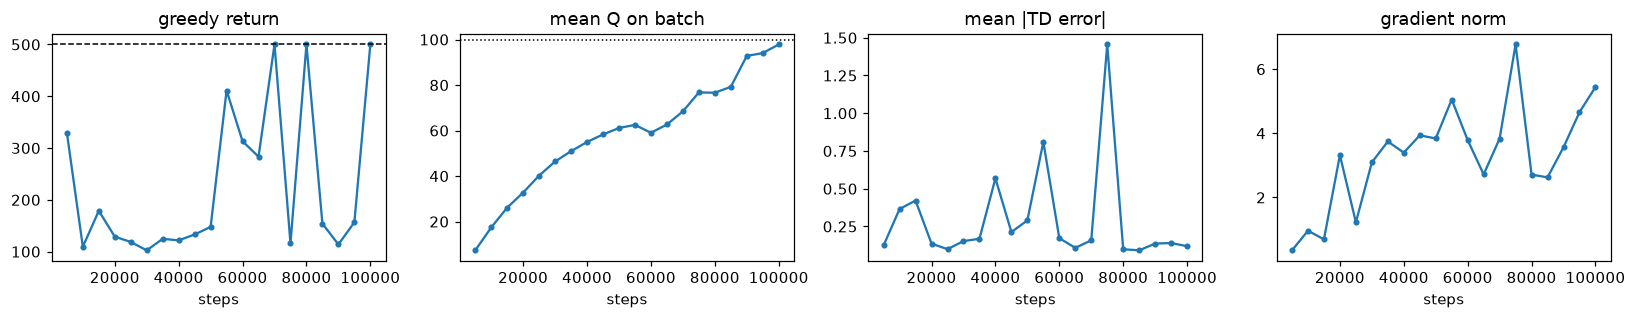

over greedy episodes: network predicts 100.09, discounted return actually 99.94


In [6]:
make = lambda: gym.make("CartPole-v1")
t0 = time.time()
net, log = dqn.train(make(), n_steps=100_000, evaluate=dqn.evaluate_gym(make), eval_every=5_000, seed=0)
print(f"({time.time() - t0:.0f} s)")
steps = [r["step"] for r in log]
fig, axs = plt.subplots(1, 4, figsize=(15, 3))
for ax, key, title in zip(axs, ["score", "q", "td", "grad"], ["greedy return", "mean Q on batch", "mean |TD error|", "gradient norm"]):
    ax.plot(steps, [r[key] for r in log], "o-", ms=3); ax.set_title(title); ax.set_xlabel("steps")
axs[0].axhline(500, color="k", ls="--", lw=1); axs[1].axhline(100, color="k", ls=":", lw=1)
plt.tight_layout(); plt.show()
predicted, actual = dqn.value_vs_return(net, make)
print(f"over greedy episodes: network predicts {predicted:.2f}, discounted return actually {actual:.2f}")

## 4. Replay and target network, removed one at a time

5 seeds × 100,000 steps per configuration, from `experiments/deep_value_sweep.py ablation`.
The shaded band is the range over seeds; the line is the median.

                  final greedy, median [min, max]  mean over curve  predicted Q   actual  peak |mean Q|
         neither               9.2 [  9.2,   9.5]              9.2 9401966700.09     4.91  10298254336.0
       no replay              49.8 [ 10.1, 500.0]             90.6       238.92    25.25          250.9
       no target               9.2 [  9.2,   9.5]              9.2 32955831091.20     4.91  30580776960.0
 replay + target             500.0 [ 46.2, 500.0]            231.3       100.09    99.94           97.8


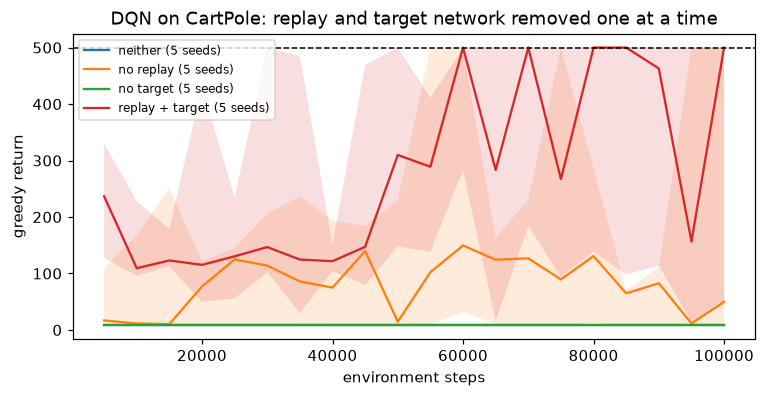

In [7]:
def load(kind):
    rows = {}
    for path in sorted(RESULTS.glob(f"{kind}__*.json")):
        r = json.loads(path.read_text()); rows.setdefault(r["name"], []).append(r)
    return rows

def curves(rows, title):
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for name, results in rows.items():
        steps = [e["step"] for e in results[0]["log"]]
        scores = np.array([[e["score"] for e in r["log"]] for r in results])
        ax.plot(steps, np.median(scores, 0), label=f"{name} ({len(results)} seeds)")
        ax.fill_between(steps, scores.min(0), scores.max(0), alpha=0.15)
    ax.axhline(500, color="k", ls="--", lw=1); ax.set_xlabel("environment steps"); ax.set_ylabel("greedy return")
    ax.set_title(title); ax.legend(fontsize=8); plt.show()

def table(rows):
    print(f"{'':>16} {'final greedy, median [min, max]':>32} {'mean over curve':>16} {'predicted Q':>12} {'actual':>8} {'peak |mean Q|':>14}")
    for name, results in rows.items():
        final = np.array([r["log"][-1]["score"] for r in results])
        area = np.median([np.mean([e["score"] for e in r["log"]]) for r in results])
        peak = np.median([max(abs(e["q"]) for e in r["log"]) for r in results])
        print(f"{name:>16} {f'{np.median(final):6.1f} [{final.min():5.1f}, {final.max():5.1f}]':>32} {area:>16.1f} "
              f"{np.median([r['predicted'] for r in results]):>12.2f} {np.median([r['actual'] for r in results]):>8.2f} {peak:>14.1f}")

ablation = load("ablation")
table(ablation)
curves(ablation, "DQN on CartPole: replay and target network removed one at a time")

Read **predicted Q** against **actual** before the return.

- **Replay + target:** prediction and reality agree (100.09 against 99.94), and 3 of 5 seeds end at 500. Two seeds collapse late, to 110.2 and 46.2. That is DQN's known instability, and the reason one seed proves nothing.
- **No target network:** Q diverges on every seed, to about $3 \times 10^{10}$, and the return falls to 9.2. Each update moves the target it chases, and here nothing stops it.
- **No replay:** Q does not diverge, but it overestimates (238.92 against 25.25), and the final return ranges from 10.1 to 500 across seeds.
- **Neither:** diverges, like no target.

On this setup the target network prevents divergence, and replay makes the seeds agree.

## 5. Maximisation bias, measured exactly

Sutton & Barto's Example 6.7 ([`envs/maximization_bias.py`](../envs/maximization_bias.py)).
From A, **right** ends with reward 0. **Left** goes to B, where each of 10 actions ends with reward −0.1 ± 1. So left is worth −0.1 and right is optimal.
Q-learning estimates $\max_b Q(B, b)$, and the max of ten noisy estimates of −0.1 is positive for a long time.
Double Q-learning ([`algos/double_q.py`](../algos/double_q.py)) lets one table pick the action and the other score it.
ε = 0.1, so pure exploration goes left 5% of the time.

exact Q(A, left) = -0.10   exact Q(A, right) = +0.00


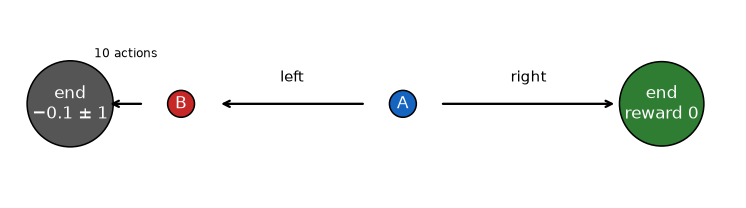

(14 s, 1,000 runs each)


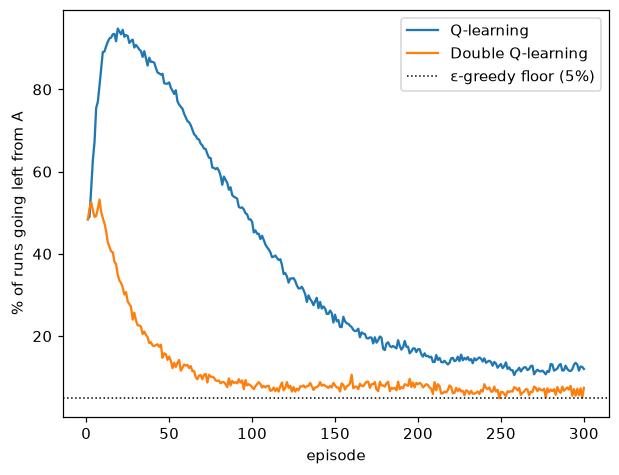

        Q-learning: episodes 11-50 left 89.0%, episodes 201-300 left 13.1%
 Double Q-learning: episodes 11-50 left 26.3%, episodes 201-300 left 6.8%


In [8]:
mb = MaximizationBias()
q = mb.true_q(1.0)
print(f"exact Q(A, left) = {q[0, 0]:+.2f}   exact Q(A, right) = {q[0, 1]:+.2f}")

fig, ax = plt.subplots(figsize=(8.5, 2.2)); ax.axis("off")
for text, xy, colour in (("A", (0.45, 0.5), "#1565c0"), ("B", (0.15, 0.5), "#c62828"),
                         ("end\nreward 0", (0.8, 0.5), "#2e7d32"), ("end\n−0.1 ± 1", (0.0, 0.5), "#555")):
    ax.text(*xy, text, ha="center", va="center", fontsize=11, color="white", bbox=dict(boxstyle="circle", fc=colour))
ax.annotate("", xy=(0.74, 0.5), xytext=(0.5, 0.5), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(0.62, 0.62, "right", ha="center")
ax.annotate("", xy=(0.2, 0.5), xytext=(0.4, 0.5), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(0.3, 0.62, "left", ha="center")
ax.annotate("", xy=(0.05, 0.5), xytext=(0.1, 0.5), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(0.075, 0.75, "10 actions", ha="center", fontsize=8)
ax.set_xlim(-0.08, 0.9); plt.show()

t0 = time.time()
RUNS = 1_000
left = {name: np.mean([double_q.run(mb, double, seed=s) for s in range(RUNS)], axis=0)
        for name, double in (("Q-learning", False), ("Double Q-learning", True))}
print(f"({time.time() - t0:.0f} s, {RUNS:,} runs each)")
for name, curve in left.items():
    plt.plot(np.arange(1, len(curve) + 1), 100 * curve, label=name)
plt.axhline(5, color="k", ls=":", lw=1, label="ε-greedy floor (5%)")
plt.xlabel("episode"); plt.ylabel("% of runs going left from A"); plt.legend(); plt.show()
for name, curve in left.items():
    print(f"{name:>18}: episodes 11-50 left {curve[10:50].mean():.1%}, episodes 201-300 left {curve[200:].mean():.1%}")

## 6. DQN, Double, Dueling, PER, 3-step, C51 and Noisy on CartPole

Each file changes one thing in `algos/dqn.py`, marked in the source:

| variant | the change | file:line |
| --- | --- | --- |
| Double DQN | online net picks $a'$, target net scores it | `double_dqn.py:65-67` |
| Dueling | network head $Q = V + A - \bar A$ | `dueling_dqn.py:34-45` |
| PER | sample by $\lvert\delta\rvert^{0.6}$, importance weights $w$, β → 1 | `per_dqn.py:119`, `141-148` |
| 3-step | $r_t + \gamma r_{t+1} + \gamma^2 r_{t+2} + \gamma^3 \max Q(s_{t+3})$ | `n_step_dqn.py:52-64`, `85-87` |
| C51 | 51 probabilities per action on atoms 0..100, projected target, cross-entropy | `c51_dqn.py`, `project` and the marked update |
| Noisy | weights $\mu + \sigma\varepsilon$, ε resampled every step, no ε-greedy | `noisy_dqn.py`, `NoisyLinear` and the marked step |

5 seeds × 100,000 steps each, from `experiments/deep_value_sweep.py compare`.

                  final greedy, median [min, max]  mean over curve  predicted Q   actual  peak |mean Q|
         c51_dqn             500.0 [116.6, 500.0]            377.7        94.92    99.00           92.9
      double_dqn             500.0 [ 80.6, 500.0]            287.1        88.05    97.51           88.1
             dqn             500.0 [ 46.2, 500.0]            231.3       100.09    99.94           97.8
     dueling_dqn             125.8 [ 90.9, 500.0]            226.9        99.23    42.31           96.2
      n_step_dqn             500.0 [ 98.3, 500.0]            407.3       101.70   100.33          101.7
       noisy_dqn             500.0 [500.0, 500.0]            307.5        99.06    99.81           96.1
         per_dqn             316.1 [115.9, 496.5]            300.2        99.57    76.44           98.8


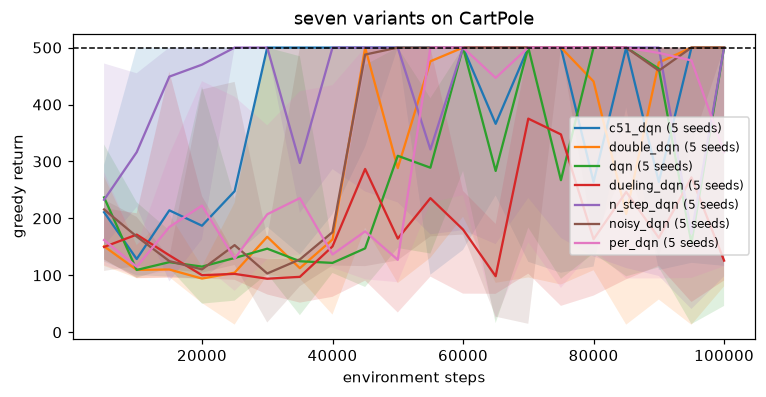

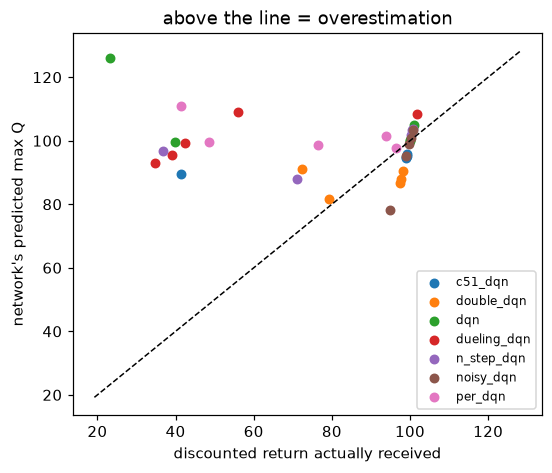

In [9]:
compare = load("compare")
table(compare)
curves(compare, "seven variants on CartPole")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for name, results in compare.items():
    ax.scatter([r["actual"] for r in results], [r["predicted"] for r in results], label=name, s=30)
lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lims, lims, "k--", lw=1); ax.set_xlabel("discounted return actually received"); ax.set_ylabel("network's predicted max Q")
ax.set_title("above the line = overestimation"); ax.legend(fontsize=8); plt.show()

- **3-step** is the clear winner here: mean over the curve 407.3 against DQN's 231.3, and every seed ends at 98.3 or above. Reward reaches three states back per update instead of one.
- **Double DQN** is the only variant that predicts **less** than it gets (88.05 against 97.51). Its curve average is second best (287.1).
- **PER** learns sooner (curve average 300.2) and ends less consistently (final median 316.1).
- **Dueling** does not beat DQN on CartPole (226.9 against 231.3).
- **C51** has the second-best curve (377.7) and ends at 500 on 4 of 5 seeds; it predicts 94.92 against 99.00 received.
- **Noisy** is the only variant that ends at 500 on all 5 seeds (curve average 307.5).

Five seeds and one environment: these rank the variants on CartPole, not in general. Rainbow's own ablation, on Atari, ranked PER and n-step as the most important, and n-step agrees here.

## 7. The last two Rainbow parts: a distribution, and learned noise

Rainbow (Hessel et al. 2017) combines six components. All six are built here as separate files; there is no single file combining them.
The Rainbow paper's own ablation found PER and n-step mattered most on Atari; CartPole is too easy to say anything about that.

**C51 learns the whole return distribution.** On CartPole that only shows as a mean. On a coin flip it can be checked exactly:
one state, reward +1 with probability 1/4 and −1 otherwise ([`diagnostics/probe_envs.py`](../diagnostics/probe_envs.py), `CoinFlip`).
DQN learns the mean, −0.5; C51 must put 1/4 of its mass on +1 and 3/4 on −1. 3,000 steps, live.

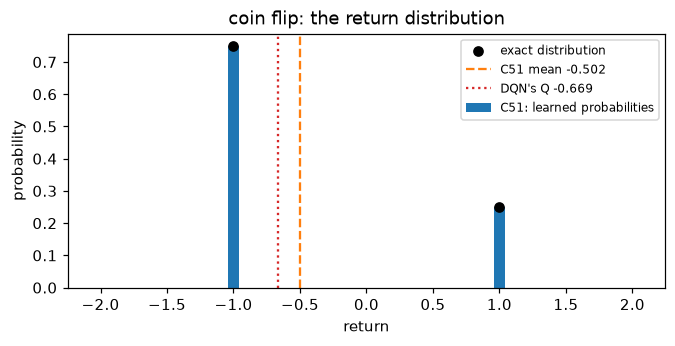

mass at +1: 0.249 (exact 0.25)   mass at -1: 0.751 (exact 0.75)   (2 s)


In [10]:
from algos import c51_dqn
from diagnostics.probe_envs import CoinFlip
t0 = time.time()
probe = dict(learning_starts=200, buffer_size=5_000, target_update=100)
coin_net, _ = c51_dqn.train(CoinFlip(), n_steps=3_000, v_min=-2.0, v_max=2.0, n_atoms=41, **probe)
dqn_net, _ = dqn.train(CoinFlip(), n_steps=3_000, **probe)
with torch.no_grad():
    p = coin_net.distribution(torch.zeros(1, 1))[0, 0].numpy()
    dqn_q = float(dqn_net(torch.zeros(1, 1))[0, 0])
z = coin_net.support.numpy()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(z, p, width=0.08, label="C51: learned probabilities")
ax.scatter([-1, 1], [0.75, 0.25], color="k", zorder=3, label="exact distribution")
ax.axvline(float((p * z).sum()), color="tab:orange", ls="--", label=f"C51 mean {float((p * z).sum()):.3f}")
ax.axvline(dqn_q, color="tab:red", ls=":", label=f"DQN's Q {dqn_q:.3f}")
ax.set_xlabel("return"); ax.set_ylabel("probability"); ax.legend(fontsize=8); ax.set_title("coin flip: the return distribution")
plt.show()
print(f"mass at +1: {p[np.argmin(abs(z - 1))]:.3f} (exact 0.25)   mass at -1: {p[np.argmin(abs(z + 1))]:.3f} (exact 0.75)"
      f"   ({time.time() - t0:.0f} s)")

**Noisy nets learn how much to explore.** Each noisy weight is $\mu + \sigma\varepsilon$, and σ is trained by the same loss as μ.
Below, the mean |σ| of the noisy layers over the 5 CartPole runs of section 6. It starts at $0.5/\sqrt{\text{fan-in}}$ = 0.044.

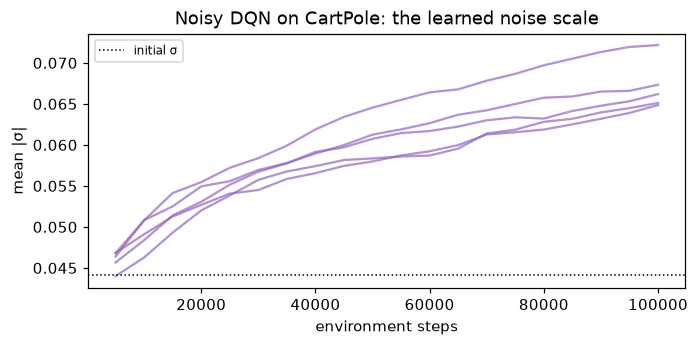

mean |σ| at the end, per seed: [0.0662, 0.0651, 0.0722, 0.0673, 0.0649]


In [11]:
fig, ax = plt.subplots(figsize=(7, 3))
for r in compare["noisy_dqn"]:
    ax.plot([e["step"] for e in r["log"]], [e["sigma"] for e in r["log"]], color="tab:purple", alpha=0.7)
ax.axhline(0.5 / np.sqrt(128), color="k", ls=":", lw=1, label="initial σ")
ax.set_xlabel("environment steps"); ax.set_ylabel("mean |σ|"); ax.set_title("Noisy DQN on CartPole: the learned noise scale")
ax.legend(fontsize=8); plt.show()
print("mean |σ| at the end, per seed:", [round(r["log"][-1]["sigma"], 4) for r in compare["noisy_dqn"]])

Measured: σ **rises** on all 5 seeds, from 0.044 to between 0.065 and 0.072 at the end, and the rise slows.
The loss is free to push σ down and does not: on CartPole the greedy policy reaches 500 with the noise on, so the noise costs little.
Learning the noise scale does not mean the noise goes away.

Whether noise beats ε-greedy where exploration is the whole problem is measured on long chains in [`exploration_01_bonus_curriculum_her.ipynb`](exploration_01_bonus_curriculum_her.ipynb), section 6.

## 8. What breaks, and how you would know

| symptom | likely cause | where to look |
| --- | --- | --- |
| probe 1 learns ≫ 1 | terminal mask missing, or termination reported as truncation | section 2 |
| probe 2 or 5 fails | network ignores the observation (wrong input, frozen layer) | the network |
| mean Q keeps climbing past ~100 on CartPole | no target network, or no terminal mask | section 4 |
| CartPole stuck near 200 | 500-step truncation treated as termination | store `terminated`, not `terminated or truncated` |
| Double DQN = DQN everywhere | the argmax is taken on the target net | `double_dqn.py:66` |
| PER replays a few transitions forever | priorities not updated, or ε = 0 | `per_dqn.py:100-103` |
| n-step values off by a factor ≈ γ^(n−1) | bootstrap discounted by γ instead of γ^k | `n_step_dqn.py:85-87` |
| C51 mean Q pinned at V_MIN or V_MAX | the support does not cover the returns | `c51_dqn.py`, `V_MIN, V_MAX` |
| C51 target rows sum to less than 1 | atoms landing on a grid point get zero weight | `c51_dqn.py`, `project` |
| Noisy DQN explores no more than greedy DQN | noise never resampled, or σ left out of the optimiser | `noisy_dqn.py`, `reset_noise` |
| Noisy evaluation scores jump between identical checkpoints | evaluating with the noise on | `net.eval()` before scoring |